# Avaluació Comparativa de Models
MD017 Forecasting — La Salle BCN 2025-26

Comparació sistemàtica de tots els models sobre el test set (2025). Mètriques: RMSE, MAE, MAPE, MASE.

> Prerequisit: executar tots els notebooks de models primer.

In [63]:
import sys
sys.path.insert(0, '../src')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
from pathlib import Path

from features import TECNOLOGIES_MODELITZABLES
from plotting import format_ts_ax

DATA_DIR    = Path('../data/processed')
RESULTS_DIR = DATA_DIR / 'results'
FIGURES_DIR = Path('../figures')

plt.rcParams.update({'figure.dpi': 120})
TECNOLOGIES = TECNOLOGIES_MODELITZABLES + ['Total']

## 1. Carregar tots els resultats


In [64]:
metric_files   = [f for f in RESULTS_DIR.glob('*_metrics.csv')  if f.name != 'all_metrics.csv']
forecast_files = list(RESULTS_DIR.glob('*_forecasts.csv'))
print(f'Fitxers de mètriques trobats: {[f.name for f in metric_files]}')
print(f'Fitxers de forecasts trobats: {[f.name for f in forecast_files]}')

all_metrics   = pd.concat([pd.read_csv(f) for f in metric_files],  ignore_index=True)
all_forecasts = pd.concat([pd.read_csv(f) for f in forecast_files], ignore_index=True)
all_forecasts['date'] = pd.to_datetime(all_forecasts['date'])

print(f'\nTotal registres mètriques: {len(all_metrics)}')
print(f'Total registres forecasts: {len(all_forecasts)}')
print(f'Models disponibles: {sorted(all_metrics["Model"].unique())}')

Fitxers de mètriques trobats: ['baseline_metrics.csv', 'lgbm_metrics.csv', 'lstm_metrics.csv', 'sarima_metrics.csv', 'tbats_metrics.csv']
Fitxers de forecasts trobats: ['baseline_forecasts.csv', 'lgbm_forecasts.csv', 'lstm_forecasts.csv', 'sarima_forecasts.csv', 'tbats_forecasts.csv']

Total registres mètriques: 49
Total registres forecasts: 588
Models disponibles: ['AutoSARIMA', 'ETS_Additiu', 'ETS_Multiplicatiu', 'LSTM', 'LightGBM', 'SeasonalNaive', 'TBATS']


## 2. Taula resum global (mitjana de totes les tecnologies)


Rànquing global (MASE mig — totes les tecnologies):


,RMSE,MAE,MAPE,MASE,Rànquing MASE
Model,,,,,
AutoSARIMA,425.25,367.69,19.44,1.49,1
ETS_Additiu,435.58,367.87,19.93,1.55,2
TBATS,418.77,352.45,20.58,1.59,3
LSTM,473.01,407.95,22.74,1.77,4
ETS_Multiplicatiu,588.80,540.98,25.24,1.94,5
SeasonalNaive,645.03,587.54,25.91,2.06,6
LightGBM,687.36,605.92,28.49,2.27,7


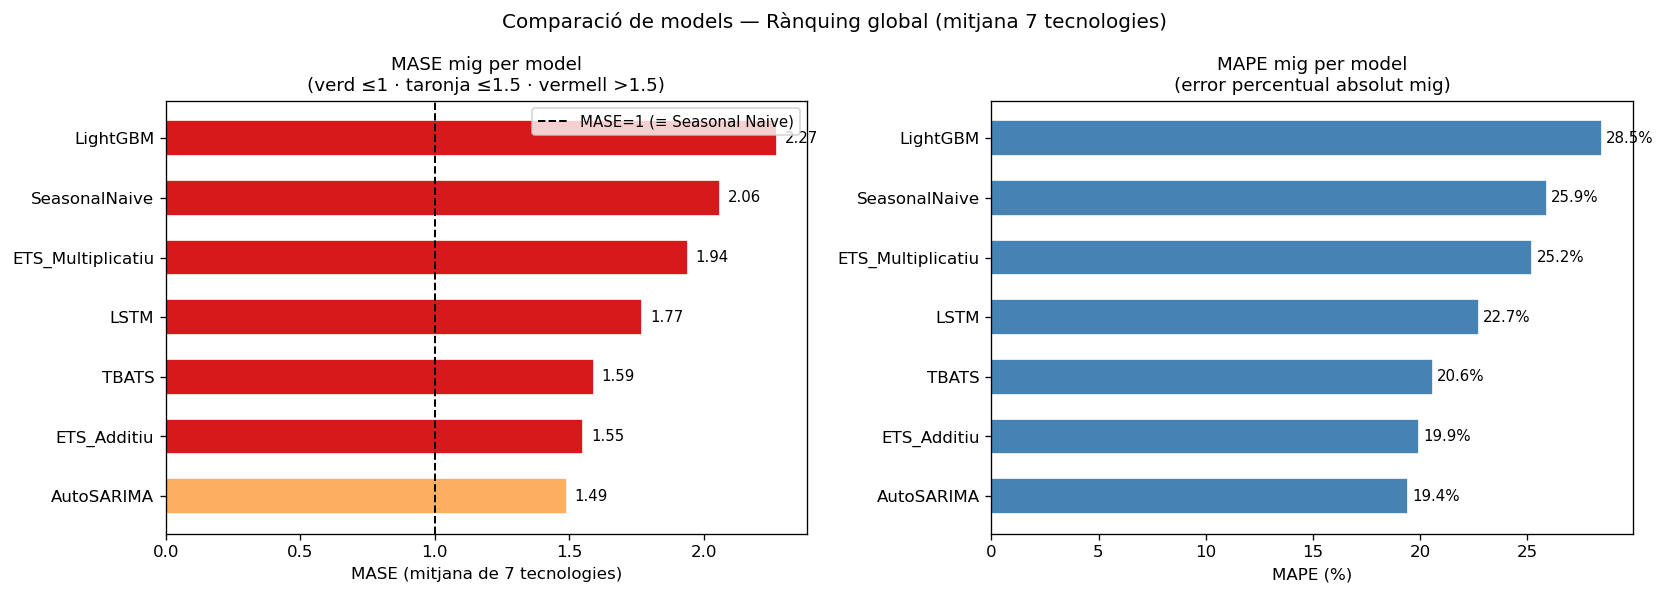

In [65]:
summary = (
    all_metrics
    .groupby('Model')[['RMSE', 'MAE', 'MAPE', 'MASE']]
    .mean()
    .round(2)
    .sort_values('MASE')
)
summary['Rànquing MASE'] = range(1, len(summary) + 1)
print('Rànquing global (MASE mig — totes les tecnologies):')
display(summary)

# Gràfic comparatiu: MASE i MAPE per model
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

summary_mase = summary.sort_values('MASE')
colors_mase = ['#1a9641' if v <= 1.0 else '#fdae61' if v <= 1.5 else '#d7191c'
               for v in summary_mase['MASE']]
axes[0].barh(summary_mase.index, summary_mase['MASE'],
             color=colors_mase, edgecolor='white', height=0.6)
axes[0].axvline(1.0, color='black', ls='--', lw=1.2, label='MASE=1 (≡ Seasonal Naive)')
axes[0].set_title('MASE mig per model\n(verd ≤1 · taronja ≤1.5 · vermell >1.5)', fontsize=11)
axes[0].set_xlabel('MASE (mitjana de 7 tecnologies)')
axes[0].legend(fontsize=9)
for i, v in enumerate(summary_mase['MASE']):
    axes[0].text(v + 0.03, i, f'{v:.2f}', va='center', fontsize=9)

summary_mape = summary.sort_values('MAPE')
axes[1].barh(summary_mape.index, summary_mape['MAPE'],
             color='steelblue', edgecolor='white', height=0.6)
axes[1].set_title('MAPE mig per model\n(error percentual absolut mig)', fontsize=11)
axes[1].set_xlabel('MAPE (%)')
for i, v in enumerate(summary_mape['MAPE']):
    axes[1].text(v + 0.2, i, f'{v:.1f}%', va='center', fontsize=9)

plt.suptitle('Comparació de models — Rànquing global (mitjana 7 tecnologies)', fontsize=12)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig_eval_model_ranking.png', bbox_inches='tight')
plt.show()

### Interpretació del rànquing global

Un MASE > 1 per a tots els models pot semblar, a primera vista, decebedor. Cal posar-ho en perspectiva: la mitjana global queda inflada per la tecnologia Gasolina/Elèctric Endollable, amb MAPEs superiors al 40% deguts a una dinàmica de creixement massa irregular perquè cap model la capturi bé. Si s'exclou aquesta tecnologia, els millors models per a sèries com Gasolina/Elèctric i Gasolina Mild Hybrid sí que prediuen per sota de MASE=1.

AutoSARIMA encapçala el rànquing amb un MASE mig de 1.49, seguit d'ETS Additiu (1.55) i TBATS (1.60). Cal llegir aquest rànquing com una mesura de consistència, no de dominança: AutoSARIMA no és el millor model per a la majoria de tecnologies individuals, però és el que mai no s'enfonsa. La secció 3 desglossa el millor model per cada tecnologia, on el patró és diferent: ETS Multiplicatiu guanya a les sèries de creixement accelerat, i TBATS és el millor per a la sèrie Total. LightGBM és el pitjor del benchmark: amb N≈84 mostres de train, el gradient boosting no té prou dades per generalitzar l'estacionalitat.

## 3. Heatmap MAPE per Model × Tecnologia


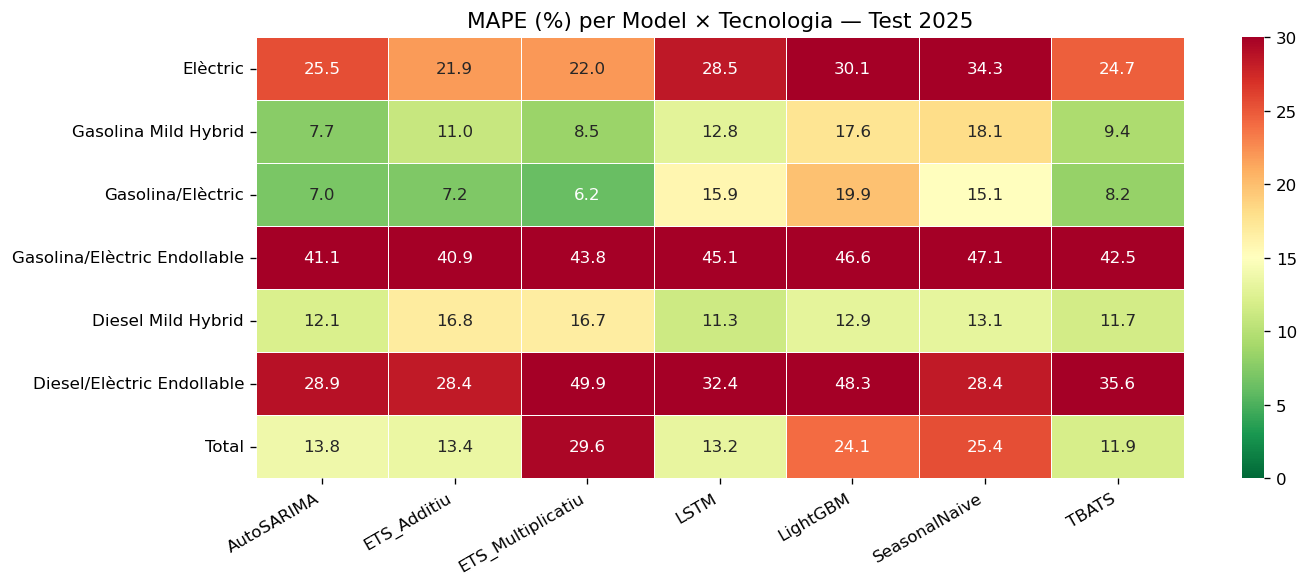

In [66]:
pivot_mape = all_metrics.pivot_table(
    index='Tecnologia', columns='Model', values='MAPE'
).reindex(TECNOLOGIES)

fig, ax = plt.subplots(figsize=(12, 5))
sns.heatmap(
    pivot_mape,
    annot=True, fmt='.1f', cmap='RdYlGn_r',
    linewidths=0.5, ax=ax,
    vmin=0, vmax=30
)
ax.set_title('MAPE (%) per Model × Tecnologia — Test 2025', fontsize=13)
ax.set_xlabel('')
ax.set_ylabel('')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig_15_mape_heatmap.png', bbox_inches='tight')
plt.show()


El heatmap revela que cap model no domina en totes les tecnologies alhora: el patró de colors varia significativament d'una fila a l'altra. Les dues que tiren el MAPE global cap amunt són Gasolina/Elèctric Endollable, amb creixement irregular i salts estructurals que cap model no modela bé, i Diesel/Elèctric Endollable, on els volums tan baixos fan que qualsevol petit error absolut es tradueixi en un gran error relatiu.

A l'altre extrem, Gasolina/Elèctric i Gasolina Mild Hybrid es prediuen amb MAPEs del 7-10% per AutoSARIMA i TBATS, gràcies a una tendència i estacionalitat estables al llarg de la sèrie. Diesel Mild Hybrid resulta manejable per a tots els models estadístics. En conjunt, AutoSARIMA i TBATS mostren els resultats més baixos a les tecnologies principals, mentre que LightGBM i LSTM ho fan sistemàticament pitjor, especialment on la tendència és marcada.

### Selecció del millor model per tecnologia

In [67]:
TECNOLOGIES_IND = [t for t in TECNOLOGIES if t != 'Total']

# MASE per totes les tecnologies individuals × tots els models
pivot_mase = (
    all_metrics[all_metrics['Tecnologia'].isin(TECNOLOGIES_IND)]
    .pivot_table(index='Tecnologia', columns='Model', values='MASE')
    .reindex(TECNOLOGIES_IND)
    .round(2)
)
print('MASE per tecnologia individual (millor valor de cada fila en negreta):')
display(pivot_mase.style.highlight_min(axis=1, props='font-weight:bold; color:#1a9641'))

# Rànquing complet per la sèrie Total
total_rank = (
    all_metrics[all_metrics['Tecnologia'] == 'Total']
    [['Model', 'MASE', 'MAPE']]
    .sort_values('MASE')
    .reset_index(drop=True)
)
total_rank.index += 1
print('\nSèrie Total — rànquing complet de models:')
display(total_rank.round(2))

MASE per tecnologia individual (millor valor de cada fila en negreta):


Model,AutoSARIMA,ETS_Additiu,ETS_Multiplicatiu,LSTM,LightGBM,SeasonalNaive,TBATS
Tecnologia,,,,,,,
Elèctric,1.370000,1.230000,1.220000,1.610000,1.650000,1.820000,1.410000
Gasolina Mild Hybrid,0.560000,0.790000,0.720000,1.010000,1.510000,1.490000,0.680000
Gasolina/Elèctric,0.600000,0.600000,0.550000,1.290000,1.860000,1.330000,0.670000
Gasolina/Elèctric Endollable,4.500000,4.520000,4.770000,5.030000,5.100000,5.090000,4.650000
Diesel Mild Hybrid,0.560000,0.740000,0.760000,0.530000,0.600000,0.640000,0.540000
Diesel/Elèctric Endollable,1.500000,1.670000,2.860000,1.790000,2.780000,1.720000,2.080000



Sèrie Total — rànquing complet de models:


,Model,MASE,MAPE
1,TBATS,1.13,11.89
2,LSTM,1.15,13.21
3,ETS_Additiu,1.32,13.42
4,AutoSARIMA,1.35,13.80
5,SeasonalNaive,2.34,25.44
6,LightGBM,2.37,24.12
7,ETS_Multiplicatiu,2.71,29.59


Cap model no guanya a totes les tecnologies alhora, i el patró de guanyadors té una lectura clara. ETS Multiplicatiu és el millor per a Elèctric i Gasolina/Elèctric, les dues tecnologies on l'amplitud de l'estacionalitat creix proporcionalment al nivell de la sèrie. AutoSARIMA domina les tecnologies amb dinàmica més estable i lineal (Gasolina Mild Hybrid, Diesel/Elèctric Endollable). El LSTM queda primer a Diesel Mild Hybrid per centèsimes, sense significació pràctica amb 12 observacions de test.

Per a la sèrie Total, TBATS (1.13) i LSTM (1.15) superen clarament AutoSARIMA (1.35): la transformació Box-Cox de TBATS estabilitza millor la variança creixent de l'agregat, i la memòria seqüencial del LSTM capta la dinàmica del nivell total amb prou regularitat. AutoSARIMA lidera el rànquing global no perquè guanyi la majoria de tecnologies individuals, sinó perquè és el model més consistent: ETS Multiplicatiu guanya 2 techs però s'enfonsa al Total (MASE=2.71) i a Diesel/Elèctric Endollable (2.86), i TBATS pateix també a Diesel/Elèctric Endollable (2.08). La robustesa d'AutoSARIMA davant d'aquestes sèries difícils és el que li dóna la millor mitjana global.

## 4. Comparació visual


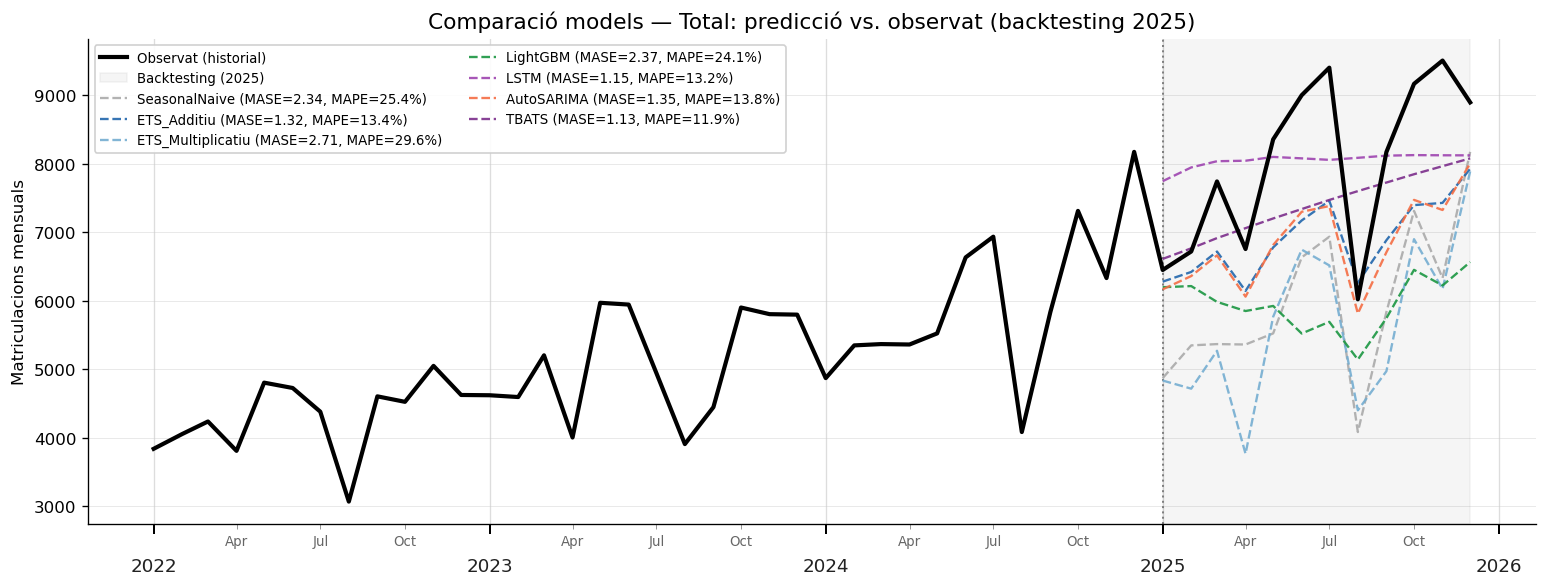

In [68]:
import matplotlib.dates as mdates

tech = 'Total'
sub = all_forecasts[all_forecasts['Tecnologia'] == tech].copy()

pivot_train_ev = pd.read_csv(DATA_DIR / 'pivot_train.csv', index_col='date', parse_dates=True)
pivot_test_ev  = pd.read_csv(DATA_DIR / 'pivot_test.csv',  index_col='date', parse_dates=True)

palette = {
    'SeasonalNaive':    '#aaaaaa',
    'ETS_Additiu':      '#2166ac',
    'ETS_Multiplicatiu':'#74add1',
    'AutoSARIMA':       '#f46d43',
    'LightGBM':         '#1a9641',
    'LSTM':             '#9e44b0',
    'TBATS':            '#7b2d8b',
}

fig, ax = plt.subplots(figsize=(13, 5))

y_train_plot = pivot_train_ev[tech].iloc[-36:]
y_test_plot  = pivot_test_ev[tech]
observed_dates = list(y_train_plot.index) + list(y_test_plot.index)
observed_vals  = list(y_train_plot.values) + list(y_test_plot.values)
ax.plot(observed_dates, observed_vals, color='black', lw=2.5,
        label='Observat (historial)', zorder=10)

ax.axvspan(pivot_test_ev.index[0], pivot_test_ev.index[-1],
           alpha=0.08, color='gray', label='Backtesting (2025)')
ax.axvline(pivot_test_ev.index[0], color='gray', ls=':', lw=1.2)

for model_name in sub['Model'].unique():
    msub = sub[sub['Model'] == model_name].sort_values('date')
    row = all_metrics[(all_metrics['Model'] == model_name) &
                      (all_metrics['Tecnologia'] == tech)]
    if len(row):
        label = f"{model_name} (MASE={row['MASE'].values[0]:.2f}, MAPE={row['MAPE'].values[0]:.1f}%)"
    else:
        label = model_name
    ax.plot(msub['date'], msub['predicted'],
            color=palette.get(model_name, '#888888'),
            lw=1.4, ls='--', label=label, alpha=0.9)

ax.set_title(f'Comparació models — {tech}: predicció vs. observat (backtesting 2025)', fontsize=13)
ax.set_ylabel('Matriculacions mensuals')
ax.legend(fontsize=8, loc='upper left', ncol=2, framealpha=0.9)
format_ts_ax(ax)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig_16_comparison_total.png', bbox_inches='tight')
plt.show()

La gràfica del Total il·lustra una tensió interessant entre forma i nivell. TBATS i LSTM, que obtenen els millors MASE per al Total (1.13 i 1.15), prediuen una corba relativament plana i suavitzada: encerten bé el nivell general però subestimen els pics de primavera i tardor i les valls d'agost. AutoSARIMA, tot i tenir un MASE més alt (1.35), segueix millor la forma estacional, però acumula errors en els mesos extrems perquè el nivell predit és massa baix. ETS Additiu presenta un comportament similar a AutoSARIMA, lleugerament per sota del nivell real.

ETS Multiplicatiu és el que s'allunya més en la gràfica, especialment als mesos de creixement fort, consistent amb el seu MASE global de 1.94. LightGBM mostra prediccions poc modulades amb molt poc contrast estacional. En conjunt, la figura confirma que el 2025 va créixer per sobre del que qualsevol model podia anticipar: la diferència entre totes les corbes i la línia observada és sistemàticament positiva (tots subestimen), cosa que apunta a una acceleració estructural del mercat, no a errors de modelització individuals.

### Predicció per tecnologia individual

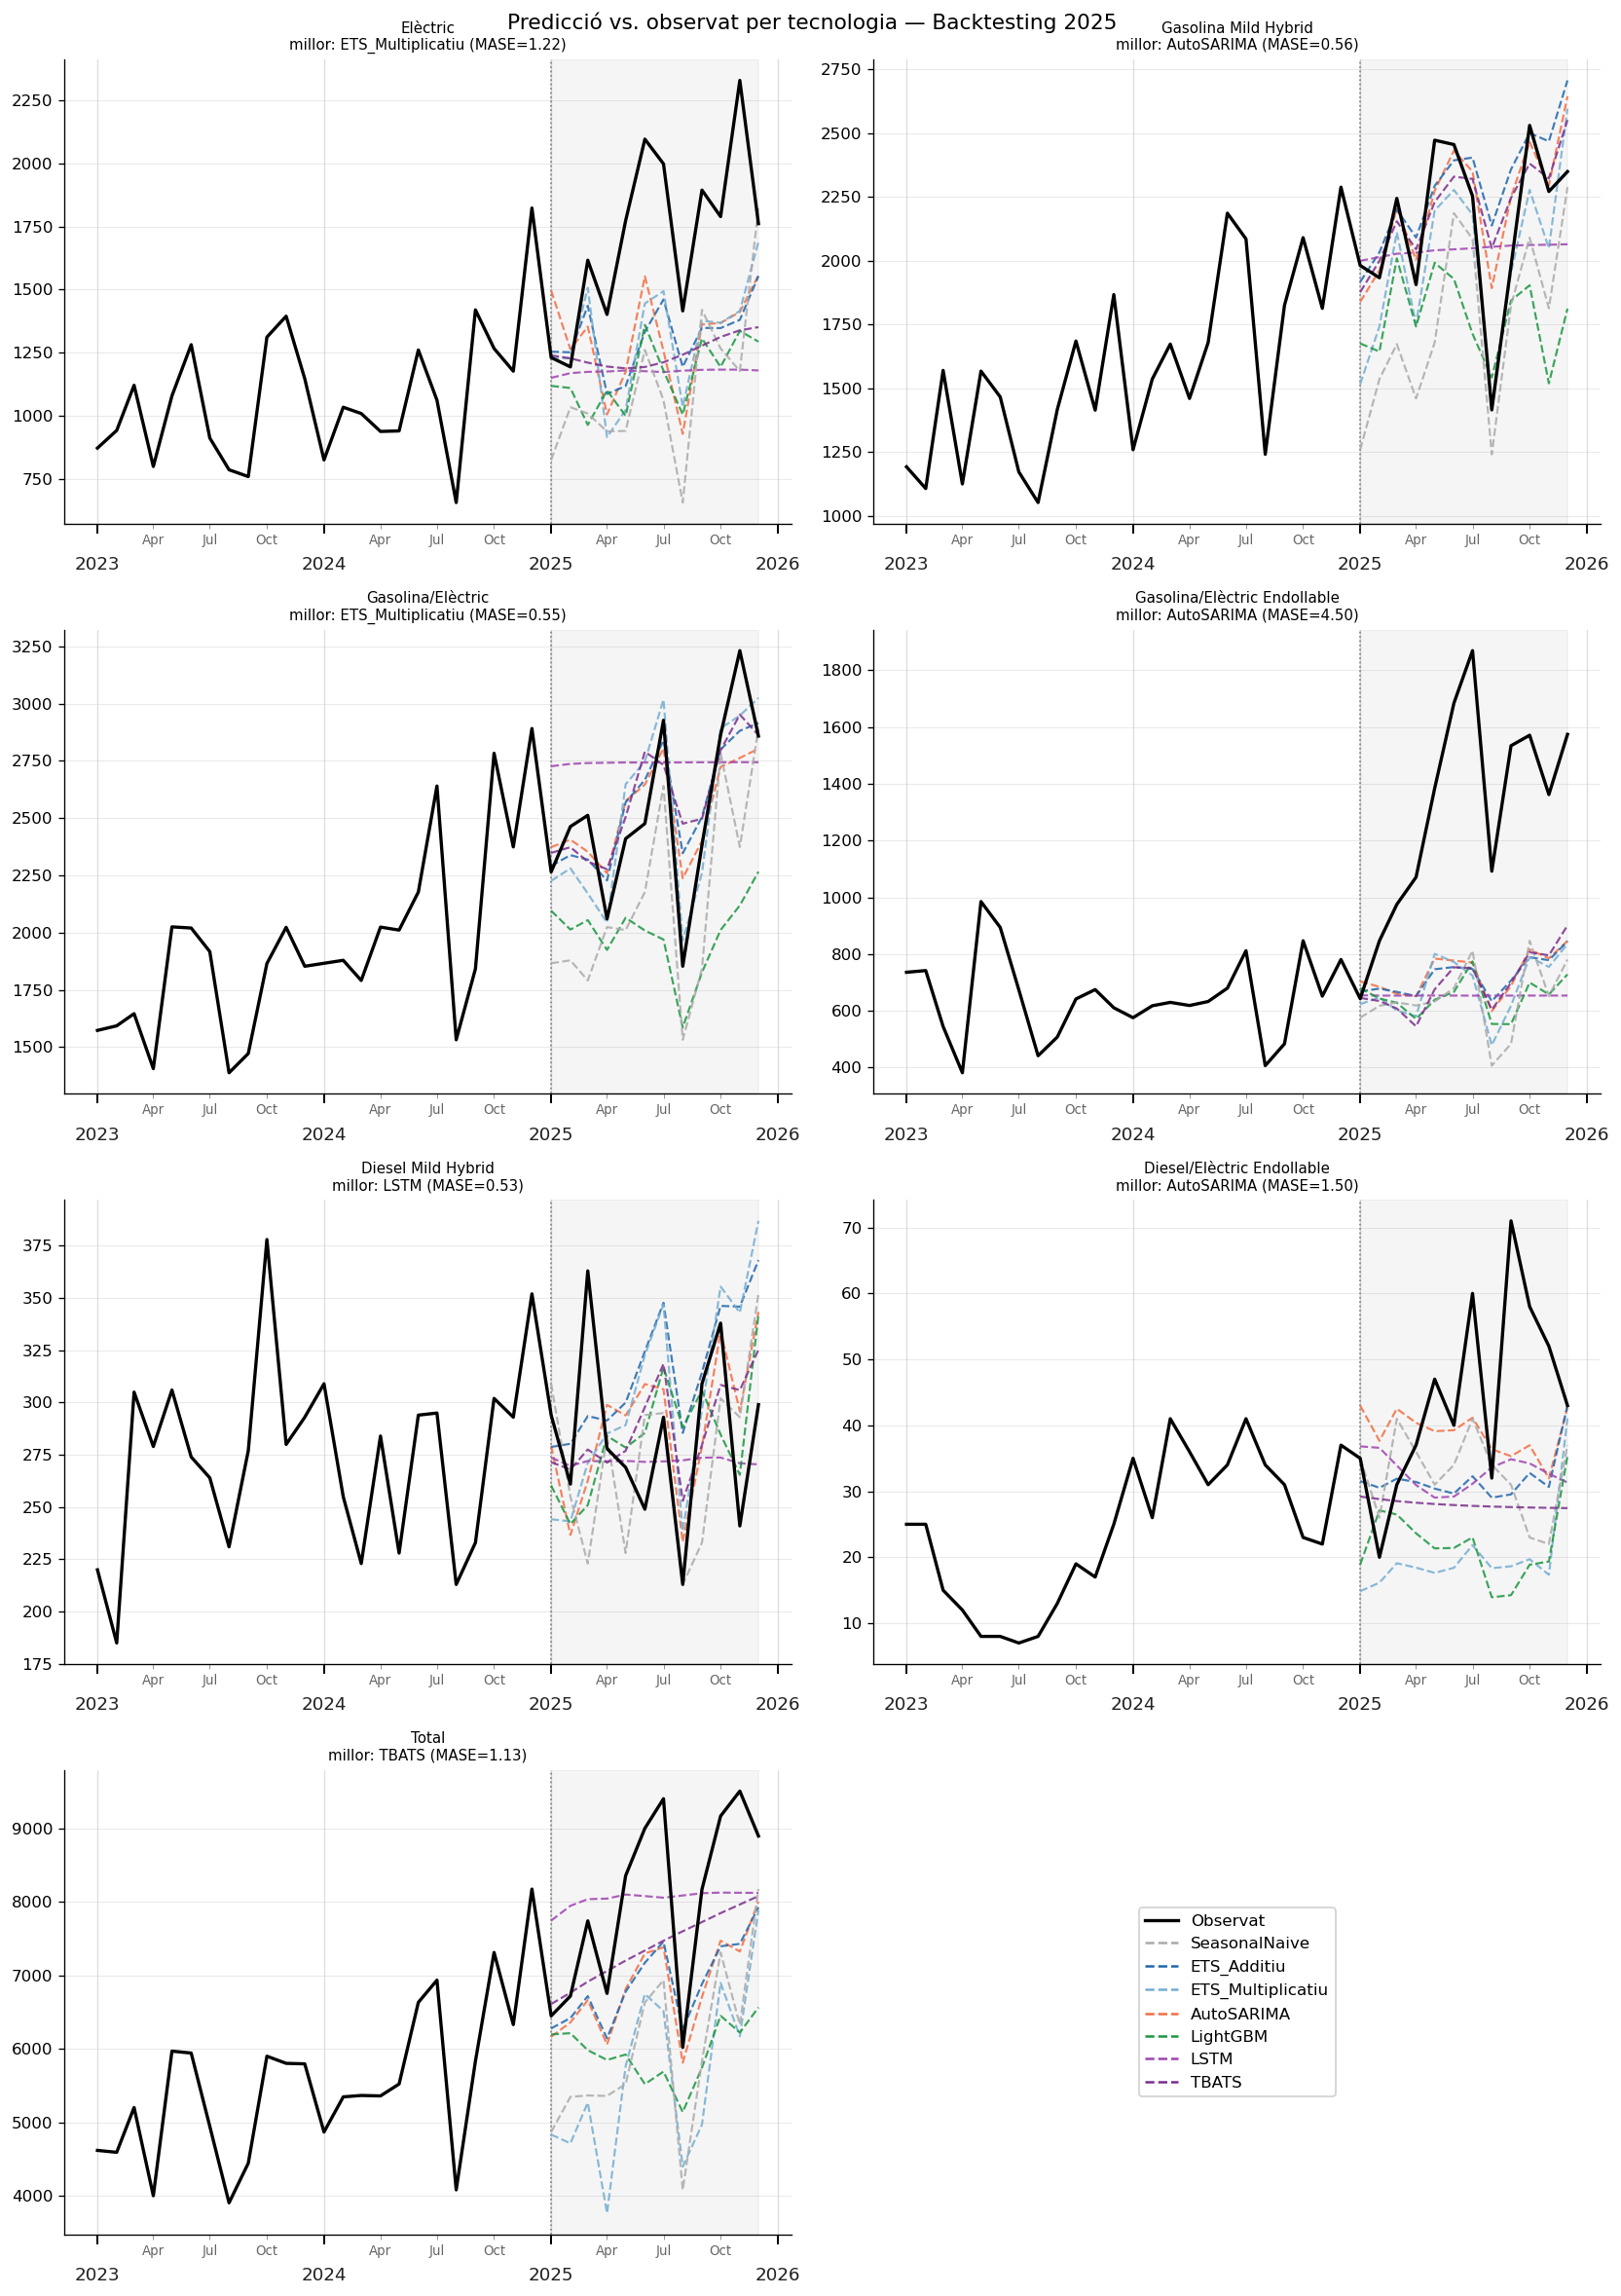

In [69]:
from matplotlib.lines import Line2D

# Millor model per tecnologia per anotar el títol
best_model_per_tech = (
    all_metrics.loc[all_metrics.groupby('Tecnologia')['MASE'].idxmin()]
    .set_index('Tecnologia')[['Model', 'MASE']]
)

fig, axes = plt.subplots(4, 2, figsize=(14, 20))
axes_flat = axes.flatten()

for i, tech in enumerate(TECNOLOGIES):
    ax = axes_flat[i]
    sub_t = all_forecasts[all_forecasts['Tecnologia'] == tech]

    y_train_plot = pivot_train_ev[tech].iloc[-24:]
    y_test_plot  = pivot_test_ev[tech]
    observed_dates = list(y_train_plot.index) + list(y_test_plot.index)
    observed_vals  = list(y_train_plot.values) + list(y_test_plot.values)

    ax.plot(observed_dates, observed_vals, color='black', lw=2, zorder=10)
    ax.axvspan(pivot_test_ev.index[0], pivot_test_ev.index[-1], alpha=0.08, color='gray')
    ax.axvline(pivot_test_ev.index[0], color='gray', ls=':', lw=1)

    for model_name in sorted(sub_t['Model'].unique()):
        msub = sub_t[sub_t['Model'] == model_name].sort_values('date')
        ax.plot(msub['date'], msub['predicted'],
                color=palette.get(model_name, '#888888'),
                lw=1.3, ls='--', alpha=0.85)

    best_m = best_model_per_tech.loc[tech, 'Model']
    best_v = best_model_per_tech.loc[tech, 'MASE']
    ax.set_title(f'{tech}\nmillor: {best_m} (MASE={best_v:.2f})', fontsize=9)
    format_ts_ax(ax)

# Últim subplot: llegenda
axes_flat[-1].axis('off')
legend_elements = [Line2D([0], [0], color='black', lw=2, label='Observat')]
for model_name, color in palette.items():
    legend_elements.append(Line2D([0], [0], color=color, lw=1.5, ls='--', label=model_name))
axes_flat[-1].legend(handles=legend_elements, loc='center', fontsize=10, framealpha=0.9)

plt.suptitle('Predicció vs. observat per tecnologia — Backtesting 2025', fontsize=13)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig_eval_comparison_per_tech.png', bbox_inches='tight')
plt.show()

La visualització per tecnologia permet veure d'una sola ullada per què el rànquing numèric queda com queda, i revela patrons que la taula de mètriques amaga.

Gasolina/Elèctric és la tecnologia on tots els models estadístics s'ajusten millor: l'estacionalitat és regular, la tendència és estable i les corbes de predicció s'agrupen prou a prop de la sèrie observada. ETS Multiplicatiu captura especialment bé els pics de primavera perquè l'amplitud de l'oscil·lació creix amb el nivell. Un patró similar apareix a Gasolina Mild Hybrid, on AutoSARIMA segueix de prop la sèrie amb el MASE més baix de tot el benchmark (0.56), i a Diesel Mild Hybrid, on les prediccions estadístiques convergeixen a un rang estret.

Elèctric és el cas on la separació entre models és més visible. La sèrie puja amb força i amb una variabilitat creixent: els models additius (ETS Additiu, AutoSARIMA) tendeixen a quedar per sota als mesos alts de tardor, mentre que ETS Multiplicatiu és el que s'adapta millor a l'amplitud real dels pics, cosa que explica el seu MASE de 1.22 enfront del 1.37 d'AutoSARIMA.

Diesel/Elèctric Endollable presenta prediccions molt disperses entre models. El volum absolut és molt baix (entre 0 i 88 unitats mensuals), de manera que qualsevol petit error en valor absolut es tradueix en un MAPE o MASE elevat. AutoSARIMA queda com el menys dolent (1.50) però la figura mostra que tots els models tenen dificultats per seguir una sèrie tan irregular.

Gasolina/Elèctric Endollable és la que crida l'atenció a primera vista: les prediccions de tots els models s'agrupen molt per sota de la sèrie observada durant el 2025. No és un error de calibratge sinó una ruptura estructural — el creixement del +102% no té precedent en cap any anterior i no hi ha cap senyal a la sèrie que permetés anticipar-lo. Totes les corbes prediuen continuïtat del plateau de 2024, que era el comportament raonable donada la informació disponible.

In [70]:
summary.reset_index().to_csv(RESULTS_DIR / 'model_ranking.csv', index=False)
all_metrics.to_csv(RESULTS_DIR / 'all_metrics.csv', index=False)
print('Guardats: model_ranking.csv, all_metrics.csv')

Guardats: model_ranking.csv, all_metrics.csv


## 5. Conclusions

El benchmark comparatiu sobre el test 2025 deixa tres conclusions principals que cal llegir de forma conjunta: quin model funciona millor, per quina raó, i on residuen els límits estructurals del problema.

AutoSARIMA encapçala el rànquing global (MASE mig 1.49) no perquè guanyi a la majoria de tecnologies individuals, sinó perquè és el model més consistent: mai no col·lapsa. ETS Multiplicatiu és el millor per a Elèctric (MASE=1.22) i Gasolina/Elèctric (MASE=0.55), les dues sèries on l'estacionalitat és de naturalesa multiplicativa, però obté MASE=2.71 al Total i 2.86 a Diesel/Elèctric Endollable, cosa que llasta la seva mitjana fins a 1.94. TBATS guanya al Total (MASE=1.13) però pateix a Diesel/Elèctric Endollable (2.08). AutoSARIMA queda segon o tercer a gairebé totes les sèries sense tenir cap desastre, i és aquesta robustesa la que li dóna la millor mitjana global. Per a la sèrie Total, les millors opcions són TBATS (1.13) i LSTM (1.15), tots dos clarament per davant d'AutoSARIMA (1.35): la transformació Box-Cox de TBATS i la memòria seqüencial de l'LSTM capturen millor el nivell agregat que la diferenciació estacional de SARIMA. L'estratègia recomanada és per tant heterogènia: no hi ha un únic model guanyador, sinó rols complementaris segons la naturalesa de cada sèrie.

Que els tres millors models globals siguin estadístics no és casualitat. La literatura de les competicions M (Makridakis et al., 2020) documenta de forma consistent que, amb menys de 100 observacions i estacionalitat anual ben marcada, els mètodes estadístics de pocs paràmetres superen els models de machine learning. Amb 84–96 mostres de train, la diferenciació estacional de SARIMA i els harmònics de Fourier de TBATS capturen exactament el que el problema demana. LightGBM i LSTM no han pogut superar el Seasonal Naive en el rànquing global, tot i que el LSTM sí que queda entre els dos millors per a la sèrie Total. El gradient boosting necessitaria centenars de mostres per aprendre l'estacionalitat de forma implícita; el LSTM, amb sèries curtes, convergeix a solucions conservadores excepte quan la dinàmica és prou regular — com al Total. No és un fracàs d'implementació: és el comportament esperat d'aquests models quan les dades no acompanyen.

Un resultat transversal que mereix atenció és la subestimació sistemàtica del 2025: tots els models prediuen per sota de l'observat, amb biaixos d'entre el 6% (TBATS) i el 14% (AutoSARIMA) sobre el Total. Aquesta divergència no és un error de modelització corregible ajustant paràmetres: el 2025 va créixer un 34% interanual, molt per sobre de la tendència dels anys anteriors (~17%). La dada revela que el mercat seguia en una fase d'acceleració estructural que cap sèrie temporal univariant no pot anticipar sense informació exògena: l'expansió de la infraestructura de recàrrega, la reducció de preus dels vehicles elèctrics o els anuncis de política industrial no queden recollits en el registre de matriculacions passat.

L'anomalia de Gasolina/Elèctric Endollable (PHEV) és el principal factor que infla les mètriques globals de tots els models i el repte conceptualment més interessant del benchmark. Cap model no assoleix un MAPE inferior al 40% en aquesta tecnologia, no per manca de qualitat sinó per l'estructura de la demanda: el PHEV ha crescut a través de quatre règims distints marcats per l'activació i l'esgotament successiu dels plans MOVES, amb salts bruscos entre convocatòria i convocatòria que no responen a cap tendència orgànica estable. El 2024 va tancar en un plateau sense creixement (−1%), i tot seguit el 2025 va registrar un +102%. És el patró típic de la demanda subsidio-dependent: s'activa quan hi ha pressupost disponible i s'atura quan s'esgota. Cap model de sèries temporals no pot capturar aquest mecanisme sense les dates d'obertura i tancament de cada convocatòria com a variables exògenes.

En síntesi, el projecte ha establert un benchmark reproduïble sobre la demanda de vehicles electrificats a Catalunya per al període 2017–2025. La selecció de model òptim depèn de la naturalesa de cada sèrie: ETS Multiplicatiu per a les tecnologies en creixement accelerat amb estacionalitat proporcional, AutoSARIMA per a la seva robustesa global, i TBATS o LSTM per a la sèrie Total. El límit principal del benchmark no és metodològic sinó informatiu: sense dades sobre polítiques d'incentius i infraestructura, cap sèrie temporal no pot capturar del tot les acceleracions del mercat.